In [1]:

import os

os.listdir('/content')



['.config', 'retail_store_inventory.csv', 'sample_data']

In [2]:

import pandas as pd

df = pd.read_csv('/content/retail_store_inventory.csv')

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Number of rows and columns: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [4]:
# Check dataset structure
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (73100, 15)

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']


In [5]:
print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())



Data types:
Date                   object
Store ID               object
Product ID             object
Category               object
Region                 object
Inventory Level         int64
Units Sold              int64
Units Ordered           int64
Demand Forecast       float64
Price                 float64
Discount                int64
Weather Condition      object
Holiday/Promotion       int64
Competitor Pricing    float64
Seasonality            object
dtype: object

Missing values in each column:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64


In [6]:
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nBasic statistics:")
display(df.describe(include="all").T)



Number of duplicate rows:
0

Basic statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,73100,731,2024-01-01,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store ID,73100,5,S001,14620,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product ID,73100,20,P0001,3655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,73100,5,Furniture,14699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,73100,4,East,18349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inventory Level,73100.0,NaN,NaN,NaN,274.469877,129.949514,50.0,162.0,273.0,387.0,500.0
Units Sold,73100.0,NaN,NaN,NaN,136.46487,108.919406,0.0,49.0,107.0,203.0,499.0
Units Ordered,73100.0,NaN,NaN,NaN,110.004473,52.277448,20.0,65.0,110.0,155.0,200.0
Demand Forecast,73100.0,NaN,NaN,NaN,141.49472,109.254076,-9.99,53.67,113.015,208.0525,518.55
Price,73100.0,NaN,NaN,NaN,55.135108,26.021945,10.0,32.65,55.05,77.86,100.0


In [7]:

# Convert Date from text to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')


In [8]:
print("Date data type:", df['Date'].dtype)
print("Invalid dates:", df['Date'].isna().sum())


Date data type: datetime64[ns]
Invalid dates: 0


In [9]:
# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [10]:
# Preview the cleaned data
display(df.head())

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [11]:
# Calculate average daily sales for each product
avg_sales = (
    df.groupby('Product ID')['Units Sold']
    .mean()
    .rename('Average Daily Sales')
)

In [12]:
# Add average sales to the dataset
df = df.merge(avg_sales, on='Product ID', how='left')

In [13]:
# Calculate estimated days of inventory remaining
df['Days of Inventory'] = (
    df['Inventory Level'] /
    df['Average Daily Sales'].replace(0, float('nan'))
)


In [14]:
# Display key columns
display(
    df[['Product ID', 'Inventory Level', 'Units Sold',
        'Average Daily Sales', 'Days of Inventory']].head(10)
)

,Product ID,Inventory Level,Units Sold,Average Daily Sales,Days of Inventory
0,P0001,231,127,136.268399,1.695184
1,P0002,204,150,133.468399,1.528452
2,P0003,102,65,134.960055,0.755779
3,P0004,469,61,135.567989,3.459519
4,P0005,166,14,137.796990,1.204671
5,P0006,138,128,136.013953,1.014602
6,P0007,359,97,136.613133,2.627859
7,P0008,380,312,133.669767,2.842827
8,P0009,183,175,137.369631,1.332172
9,P0010,108,28,135.832832,0.795095


In [15]:
import numpy as np

# Classify inventory coverage
df['Inventory Risk'] = np.select(
    [
        df['Days of Inventory'] < 3,
        df['Days of Inventory'] < 7
    ],
    [
        'High Risk',
        'Medium Risk'
    ],
    default='Low Risk'
)

In [16]:
# Summarize records by risk category
risk_summary = (
    df['Inventory Risk']
    .value_counts()
    .rename_axis('Risk Level')
    .reset_index(name='Number of Records')
)

risk_summary['Percentage'] = (
    risk_summary['Number of Records'] / len(df) * 100
).round(2)

display(risk_summary)


,Risk Level,Number of Records,Percentage
0,High Risk,58411,79.91
1,Medium Risk,14689,20.09


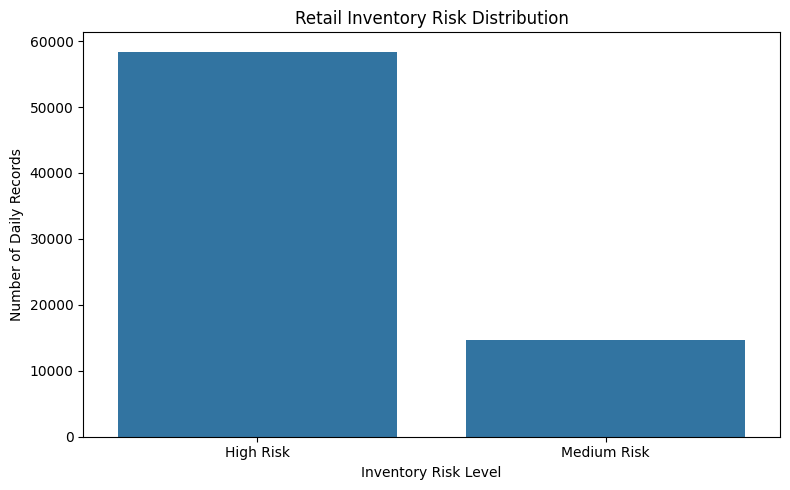

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_summary,
    x='Risk Level',
    y='Number of Records'
)

plt.title('Retail Inventory Risk Distribution')
plt.xlabel('Inventory Risk Level')
plt.ylabel('Number of Daily Records')
plt.tight_layout()
plt.show()


In [18]:
# Summarize inventory metrics by product
product_summary = (
    df.groupby(['Product ID', 'Category'], as_index=False)
    .agg(
        Average_Inventory=('Inventory Level', 'mean'),
        Average_Daily_Sales=('Units Sold', 'mean'),
        Average_Demand_Forecast=('Demand Forecast', 'mean'),
        Average_Days_of_Inventory=('Days of Inventory', 'mean')
    )
)

In [19]:
# Show products with the lowest estimated inventory coverage
product_summary = product_summary.sort_values(
    by='Average_Days_of_Inventory',
    ascending=True
)

display(product_summary.head(10).round(2))


,Product ID,Category,Average_Inventory,Average_Daily_Sales,Average_Demand_Forecast,Average_Days_of_Inventory
95,P0020,Clothing,267.28,129.52,134.33,1.92
91,P0019,Electronics,263.32,132.19,136.85,1.93
0,P0001,Clothing,266.20,133.36,138.51,1.95
51,P0011,Electronics,267.33,132.83,137.61,1.96
74,P0015,Toys,271.64,134.47,139.25,1.96
44,P0009,Toys,269.49,137.17,142.63,1.96
23,P0005,Groceries,270.34,136.69,141.45,1.96
70,P0015,Clothing,272.37,138.70,143.87,1.96
67,P0014,Furniture,273.00,135.85,140.68,1.97
75,P0016,Clothing,273.49,135.08,139.97,1.97


In [20]:
# Summarize actual sales and forecast by product
forecast_analysis = (
    df.groupby(['Product ID', 'Category'], as_index=False)
    .agg(
        Average_Units_Sold=('Units Sold', 'mean'),
        Average_Demand_Forecast=('Demand Forecast', 'mean')
    )
)

In [21]:
# Calculate forecast difference
forecast_analysis['Forecast Gap'] = (
    forecast_analysis['Average_Units_Sold']
    - forecast_analysis['Average_Demand_Forecast']
)

In [22]:
# Sort by the largest positive gap
forecast_analysis = forecast_analysis.sort_values(
    by='Forecast Gap',
    ascending=False
)

display(forecast_analysis.head(10).round(2))


,Product ID,Category,Average_Units_Sold,Average_Demand_Forecast,Forecast Gap
96,P0020,Electronics,145.27,149.49,-4.22
57,P0012,Furniture,142.09,146.39,-4.30
68,P0014,Groceries,139.98,144.39,-4.41
42,P0009,Furniture,136.86,141.32,-4.46
94,P0019,Toys,136.93,141.46,-4.53
48,P0010,Groceries,133.31,137.86,-4.55
33,P0007,Groceries,142.45,147.03,-4.57
28,P0006,Groceries,137.67,142.27,-4.60
71,P0015,Electronics,140.25,144.86,-4.61
46,P0010,Electronics,133.12,137.73,-4.61


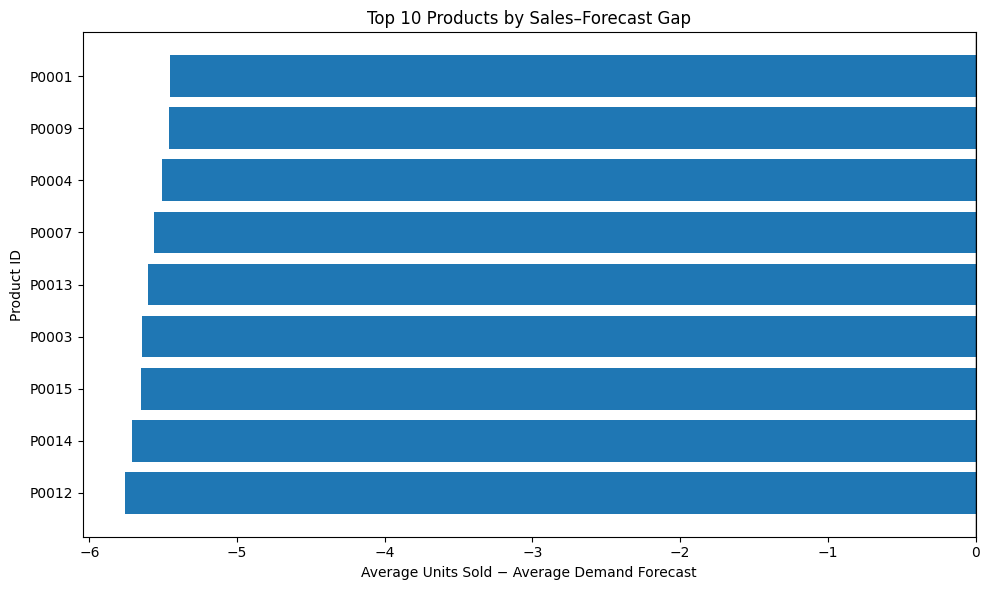

In [23]:
gap_plot = (
    forecast_analysis
    .reindex(
        forecast_analysis['Forecast Gap']
        .abs()
        .sort_values(ascending=False)
        .index
    )
    .head(10)
    .sort_values('Forecast Gap')
)

plt.figure(figsize=(10, 6))
plt.barh(gap_plot['Product ID'], gap_plot['Forecast Gap'])
plt.axvline(0, color='black', linewidth=1)

plt.title('Top 10 Products by Sales–Forecast Gap')
plt.xlabel('Average Units Sold − Average Demand Forecast')
plt.ylabel('Product ID')

plt.tight_layout()
plt.show()

In [24]:
# Calculate average daily sales for each store-product combination
store_product_sales = (
    df.groupby(['Store ID', 'Product ID'])['Units Sold']
    .mean()
    .reset_index(name='Average Daily Sales')
)

In [25]:
# Calculate average inventory for each store-product combination
store_product_inventory = (
    df.groupby(['Store ID', 'Product ID', 'Category'], as_index=False)
    .agg(Average_Inventory=('Inventory Level', 'mean'))
)

In [26]:
# Combine the summaries
priority_df = store_product_inventory.merge(
    store_product_sales,
    on=['Store ID', 'Product ID'],
    how='left'
)

In [27]:
# Estimate days of inventory coverage
priority_df['Days of Inventory'] = (
    priority_df['Average_Inventory']
    / priority_df['Average Daily Sales'].replace(0, float('nan'))
)

In [28]:
display(
    priority_df.sort_values('Days of Inventory')
    .head(10)
    .round(2)
)

,Store ID,Product ID,Category,Average_Inventory,Average Daily Sales,Days of Inventory
470,S005,P0015,Clothing,263.90,149.25,1.77
198,S002,P0020,Groceries,257.58,144.11,1.79
100,S002,P0001,Clothing,259.93,145.01,1.79
191,S002,P0019,Electronics,236.39,131.83,1.79
473,S005,P0015,Groceries,270.67,149.25,1.81
101,S002,P0001,Electronics,263.14,145.01,1.81
419,S005,P0004,Toys,248.23,135.21,1.84
1,S001,P0001,Electronics,253.05,137.31,1.84
303,S004,P0001,Groceries,255.90,138.54,1.85
195,S002,P0020,Clothing,266.26,144.11,1.85


In [29]:
import numpy as np

priority_df['Replenishment Priority'] = np.select(
    [
        priority_df['Days of Inventory'] < 3,
        priority_df['Days of Inventory'] < 7
    ],
    [
        'High',
        'Medium'
    ],
    default='Low'
)

# Count combinations in each priority category
priority_summary = (
    priority_df['Replenishment Priority']
    .value_counts()
    .rename_axis('Priority')
    .reset_index(name='Store-Product Combinations')
)

priority_summary['Percentage'] = (
    priority_summary['Store-Product Combinations']
    / len(priority_df) * 100
).round(2)

display(priority_summary)

,Priority,Store-Product Combinations,Percentage
0,High,500,100.0


In [30]:
# Sort combinations by estimated inventory coverage
replenishment_list = priority_df.sort_values(
    by='Days of Inventory',
    ascending=True,
    na_position='last'
).copy()

# Keep the most useful business columns
replenishment_list = replenishment_list[
    [
        'Store ID',
        'Product ID',
        'Category',
        'Average_Inventory',
        'Average Daily Sales',
        'Days of Inventory',
        'Replenishment Priority'
    ]
].round(2)

display(replenishment_list.head(20))

,Store ID,Product ID,Category,Average_Inventory,Average Daily Sales,Days of Inventory,Replenishment Priority
470,S005,P0015,Clothing,263.90,149.25,1.77,High
198,S002,P0020,Groceries,257.58,144.11,1.79,High
100,S002,P0001,Clothing,259.93,145.01,1.79,High
191,S002,P0019,Electronics,236.39,131.83,1.79,High
473,S005,P0015,Groceries,270.67,149.25,1.81,High
101,S002,P0001,Electronics,263.14,145.01,1.81,High
419,S005,P0004,Toys,248.23,135.21,1.84,High
1,S001,P0001,Electronics,253.05,137.31,1.84,High
303,S004,P0001,Groceries,255.90,138.54,1.85,High
195,S002,P0020,Clothing,266.26,144.11,1.85,High


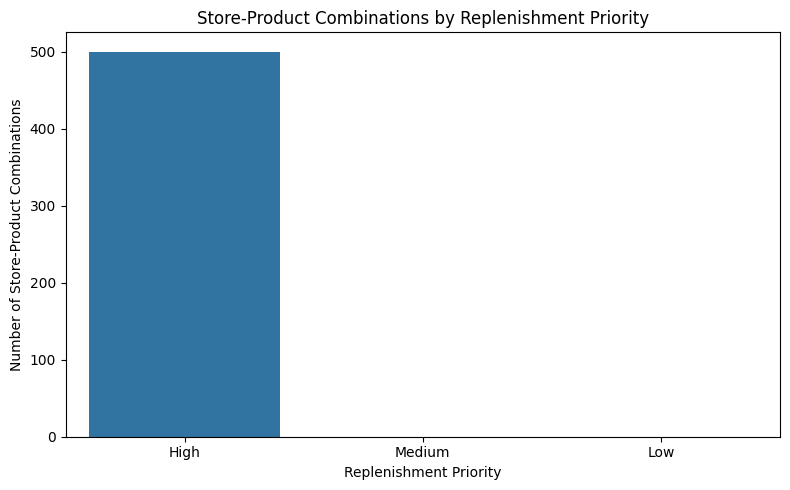

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=priority_df,
    x='Replenishment Priority',
    order=['High', 'Medium', 'Low']
)

plt.title('Store-Product Combinations by Replenishment Priority')
plt.xlabel('Replenishment Priority')
plt.ylabel('Number of Store-Product Combinations')

plt.tight_layout()
plt.show()

In [32]:
total_records = len(df)
total_stores = df['Store ID'].nunique()
total_products = df['Product ID'].nunique()

avg_daily_sales = df['Units Sold'].mean()
avg_inventory = df['Inventory Level'].mean()
avg_demand_forecast = df['Demand Forecast'].mean()

high_priority = (
    priority_df['Replenishment Priority'] == 'High'
).sum()

high_priority_pct = (
    high_priority / len(priority_df) * 100
)

print("===== INVENTORY ANALYSIS KPI SUMMARY =====")
print("Daily records:", total_records)
print("Unique stores:", total_stores)
print("Unique products:", total_products)
print("Average units sold per record:", round(avg_daily_sales, 2))
print("Average inventory per record:", round(avg_inventory, 2))
print("Average demand forecast per record:", round(avg_demand_forecast, 2))
print("High-priority store-product combinations:", high_priority)
print("High-priority percentage:", round(high_priority_pct, 2), "%")

===== INVENTORY ANALYSIS KPI SUMMARY =====
Daily records: 73100
Unique stores: 5
Unique products: 20
Average units sold per record: 136.46
Average inventory per record: 274.47
Average demand forecast per record: 141.49
High-priority store-product combinations: 500
High-priority percentage: 100.0 %


In [33]:
# Calculate the number of combinations in each priority category
priority_counts = priority_df['Replenishment Priority'].value_counts()

high_count = int(priority_counts.get('High', 0))
medium_count = int(priority_counts.get('Medium', 0))
low_count = int(priority_counts.get('Low', 0))

print("===== BUSINESS INSIGHTS & RECOMMENDATIONS =====\n")

print(f"1. {high_count} store-product combinations have estimated inventory coverage below 3 days.")
print("   Recommendation: Review these combinations first and verify current stock before reordering.\n")

print(f"2. {medium_count} combinations have estimated inventory coverage from 3 to under 7 days.")
print("   Recommendation: Monitor sales and supplier lead times to decide whether replenishment is needed.\n")

print(f"3. {low_count} combinations have estimated inventory coverage of 7 days or more.")
print("   Recommendation: Review these periodically to avoid unnecessary orders or excess stock.\n")

print("4. Inventory coverage uses historical average sales.")
print("   Recommendation: Consider supplier lead times, upcoming promotions, and recent sales before making final decisions.")

===== BUSINESS INSIGHTS & RECOMMENDATIONS =====

1. 500 store-product combinations have estimated inventory coverage below 3 days.
   Recommendation: Review these combinations first and verify current stock before reordering.

2. 0 combinations have estimated inventory coverage from 3 to under 7 days.
   Recommendation: Monitor sales and supplier lead times to decide whether replenishment is needed.

3. 0 combinations have estimated inventory coverage of 7 days or more.
   Recommendation: Review these periodically to avoid unnecessary orders or excess stock.

4. Inventory coverage uses historical average sales.
   Recommendation: Consider supplier lead times, upcoming promotions, and recent sales before making final decisions.


In [34]:
# Export the replenishment priority list
replenishment_list.to_csv(
    'replenishment_priority_list.csv',
    index=False
)

# Export priority summary
priority_summary.to_csv(
    'replenishment_priority_summary.csv',
    index=False
)

# Export sales vs forecast analysis
forecast_analysis.to_csv(
    'sales_forecast_gap_analysis.csv',
    index=False
)

print("Project result files created successfully!")

Project result files created successfully!


In [35]:
from google.colab import files

files.download('replenishment_priority_list.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
report = f"""
INVENTORY RISK & REPLENISHMENT PRIORITIZATION ANALYSIS
=====================================================

1. PROJECT OBJECTIVE
Analyze retail inventory and sales data to identify store-product
combinations with potentially low inventory coverage.

2. DATASET OVERVIEW
Total daily records: {len(df)}
Unique stores: {df['Store ID'].nunique()}
Unique products: {df['Product ID'].nunique()}
Dataset columns: {len(df.columns)}

3. KEY METRICS
Average units sold per record: {df['Units Sold'].mean():.2f}
Average inventory per record: {df['Inventory Level'].mean():.2f}
Average demand forecast per record: {df['Demand Forecast'].mean():.2f}

4. REPLENISHMENT PRIORITIES
High priority (<3 estimated coverage days): {(priority_df['Replenishment Priority'] == 'High').sum()}
Medium priority (3 to <7 days): {(priority_df['Replenishment Priority'] == 'Medium').sum()}
Low priority (>=7 days): {(priority_df['Replenishment Priority'] == 'Low').sum()}

5. RECOMMENDATIONS
- Review low-coverage combinations first.
- Check supplier lead times before placing replenishment orders.
- Monitor sales and inventory regularly.
- Investigate products where average sales differ substantially from forecasts.

6. LIMITATIONS
- The dataset is synthetic and does not represent a real retailer.
- Priority thresholds are illustrative assumptions.
- Inventory coverage uses historical average sales and is not a guaranteed
  stockout prediction.
- Further analysis should consider recent sales, supplier lead times,
  promotions, and formal forecast-accuracy metrics.

TOOLS
Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab
"""

with open('Inventory_Risk_Project_Report.txt', 'w') as file:
    file.write(report)

print(report)



INVENTORY RISK & REPLENISHMENT PRIORITIZATION ANALYSIS

1. PROJECT OBJECTIVE
Analyze retail inventory and sales data to identify store-product
combinations with potentially low inventory coverage.

2. DATASET OVERVIEW
Total daily records: 73100
Unique stores: 5
Unique products: 20
Dataset columns: 18

3. KEY METRICS
Average units sold per record: 136.46
Average inventory per record: 274.47
Average demand forecast per record: 141.49

4. REPLENISHMENT PRIORITIES
High priority (<3 estimated coverage days): 500
Medium priority (3 to <7 days): 0
Low priority (>=7 days): 0

5. RECOMMENDATIONS
- Review low-coverage combinations first.
- Check supplier lead times before placing replenishment orders.
- Monitor sales and inventory regularly.
- Investigate products where average sales differ substantially from forecasts.

6. LIMITATIONS
- The dataset is synthetic and does not represent a real retailer.
- Priority thresholds are illustrative assumptions.
- Inventory coverage uses historical avera

In [37]:
from google.colab import files
files.download('Inventory_Risk_Project_Report.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
print("===== FINAL PROJECT CHECK =====")

print("Dataset loaded:", not df.empty)
print("Date converted:", pd.api.types.is_datetime64_any_dtype(df['Date']))
print("Missing values:", int(df.isna().sum().sum()))
print("Priority table created:", 'Replenishment Priority' in priority_df.columns)
print("Replenishment list created:", not replenishment_list.empty)
print("Forecast gap analysis created:", not forecast_analysis.empty)

print("\nPriority counts:")
print(priority_df['Replenishment Priority'].value_counts())

print("\nTop 5 combinations for review:")
display(replenishment_list.head().round(2))

===== FINAL PROJECT CHECK =====
Dataset loaded: True
Date converted: True
Missing values: 0
Priority table created: True
Replenishment list created: True
Forecast gap analysis created: True

Priority counts:
Replenishment Priority
High    500
Name: count, dtype: int64

Top 5 combinations for review:


,Store ID,Product ID,Category,Average_Inventory,Average Daily Sales,Days of Inventory,Replenishment Priority
470,S005,P0015,Clothing,263.90,149.25,1.77,High
198,S002,P0020,Groceries,257.58,144.11,1.79,High
100,S002,P0001,Clothing,259.93,145.01,1.79,High
191,S002,P0019,Electronics,236.39,131.83,1.79,High
473,S005,P0015,Groceries,270.67,149.25,1.81,High
